In [1]:
!pip install -q ultralytics roboflow pyyaml

import os
import glob
import random
import shutil
import yaml
from roboflow import Roboflow

# 1. Download Dataset from Roboflow
rf = Roboflow(api_key="1N0g9BArJN6RF722kHfR")
project = rf.workspace("abdullahs-workspace-onigf").project("plastic-waste-resin-dataset")
version = project.version(1)
dataset = version.download("yolov8")

raw_dir = dataset.location
print(f"[+] Roboflow downloaded files to: {raw_dir}")

# 2. Gather All Images and Labels Across the Downloaded Folder
raw_images = glob.glob(os.path.join(raw_dir, "**", "*.jpg"), recursive=True) + \
             glob.glob(os.path.join(raw_dir, "**", "*.png"), recursive=True) + \
             glob.glob(os.path.join(raw_dir, "**", "*.jpeg"), recursive=True)

# Remove duplicates if any
raw_images = list(set(raw_images))
print(f"[+] Total raw images found: {len(raw_images)}")

# 3. Create Clean Output Structure
master_dir = "/content/master_dataset"
if os.path.exists(master_dir):
    shutil.rmtree(master_dir)

splits = ["train", "valid", "test"]
for split in splits:
    os.makedirs(os.path.join(master_dir, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(master_dir, split, "labels"), exist_ok=True)

# 4. Shuffle & Split (80% Train, 10% Val, 10% Test)
random.seed(42)
random.shuffle(raw_images)

total_count = len(raw_images)
val_count = int(total_count * 0.10)
test_count = int(total_count * 0.10)

val_imgs = raw_images[:val_count]
test_imgs = raw_images[val_count : val_count + test_count]
train_imgs = raw_images[val_count + test_count :]

# Helper function to move image and corresponding .txt label
def move_split(file_list, split_name):
    img_dest = os.path.join(master_dir, split_name, "images")
    lbl_dest = os.path.join(master_dir, split_name, "labels")

    for img_path in file_list:
        file_name = os.path.basename(img_path)
        base_name = os.path.splitext(file_name)[0]

        # Copy image
        shutil.copy(img_path, os.path.join(img_dest, file_name))

        # Find and copy corresponding text label if present
        lbl_path = os.path.join(os.path.dirname(img_path), "..", "labels", base_name + ".txt")
        if not os.path.exists(lbl_path):
            lbl_path = os.path.join(os.path.dirname(img_path), base_name + ".txt")

        if os.path.exists(lbl_path):
            shutil.copy(lbl_path, os.path.join(lbl_dest, base_name + ".txt"))

move_split(train_imgs, "train")
move_split(val_imgs, "valid")
move_split(test_imgs, "test")

print(f"✓ Manual Split Complete!")
print(f"  └─ Train: {len(train_imgs)} | Val: {len(val_imgs)} | Test: {len(test_imgs)}")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.7/45.7 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 39.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 302.3/302.3 kB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 74.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 123.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 6.7 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Plastic-Waste-Resin-Dataset-1 in yolov8:: 100%|██████████| 2339/2339 [00:00<00:00, 5910.06it/s]


Creating new Ultralytics Settings v0.0.7 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
[+] Roboflow downloaded files to: /content/Plastic-Waste-Resin-Dataset-1
[+] Total raw images found: 1168
✓ Manual Split Complete!
  └─ Train: 936 | Val: 116 | Test: 116


In [2]:
yaml_path = os.path.join(master_dir, "data.yaml")

yaml_content = {
    'path': master_dir,
    'train': 'train/images',
    'val': 'valid/images',
    'test': 'test/images',
    'names': {
        0: '1-PET',
        1: '2-HDPE',
        2: '3-PVC',
        3: '4-LDPE',
        4: '5-PP',
        5: '6-PS',
        6: '7-OTHER'
    }
}

with open(yaml_path, 'w') as f:
    yaml.dump(yaml_content, f, default_flow_style=False)

print("✓ Fresh data.yaml written to:", yaml_path)

✓ Fresh data.yaml written to: /content/master_dataset/data.yaml


In [3]:
!pip install -q timm pandas tabulate

import os
import pandas as pd
from ultralytics import YOLO

# 1. Setup paths
master_dir = "/content/master_dataset"
yaml_path = os.path.join(master_dir, "data.yaml")
yolo_project_dir = "/content/thesis_yolo_results"

# 2. Define the 5 YOLO models (including YOLOv12 and YOLO11)
yolo_models = {
    "YOLOv8n": "yolov8n.pt",
    "YOLOv9t": "yolov9t.pt",
    "YOLOv10n": "yolov10n.pt",
    "YOLO11n": "yolo11n.pt",
    "YOLOv12n": "yolov12n.pt"  # Latest generation
}

yolo_metrics = []

print("==========================================")
print("   STARTING YOLO BENCHMARK (5 MODELS)    ")
print("==========================================")

for model_name, weights in yolo_models.items():
    print(f"\n[+] Training {model_name}...")

    try:
        # Load weights
        model = YOLO(weights)

        # Train model
        model.train(
            data=yaml_path,
            epochs=50,             # Adjust epochs based on your compute limits
            imgsz=640,
            batch=16,
            project=yolo_project_dir,
            name=model_name,
            save=True,
            verbose=False
        )

        # Evaluate on the unseen 10% Test Split
        print(f"[+] Evaluating {model_name} on Test Set...")
        metrics = model.val(data=yaml_path, split='test')

        yolo_metrics.append({
            "Model Category": "Object Detection",
            "Architecture": model_name,
            "Precision": round(float(metrics.box.mp), 4),
            "Recall": round(float(metrics.box.mr), 4),
            "mAP50": round(float(metrics.box.map50), 4),
            "mAP50-95": round(float(metrics.box.map), 4)
        })
        print(f"✓ {model_name} Finished - mAP50: {metrics.box.map50:.4f}")

    except Exception as e:
        print(f"❌ Error training {model_name}: {e}")

# Convert YOLO results to DataFrame
df_yolo = pd.DataFrame(yolo_metrics)
print("\n=== YOLO BENCHMARK COMPLETE ===")
print(df_yolo.to_markdown(index=False))

   STARTING YOLO BENCHMARK (5 MODELS)    

[+] Training YOLOv8n...
Ultralytics 8.4.124 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/master_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.

In [4]:
import cv2

def create_cnn_crop_dataset():
    cnn_dir = "/content/cnn_dataset"

    for split in ["train", "test"]:
        img_dir = os.path.join(master_dir, split, "images")
        lbl_dir = os.path.join(master_dir, split, "labels")

        for img_name in os.listdir(img_dir):
            if not img_name.lower().endswith(('.jpg', '.jpeg', '.png')):
                continue

            img_path = os.path.join(img_dir, img_name)
            lbl_path = os.path.join(lbl_dir, os.path.splitext(img_name)[0] + ".txt")

            image = cv2.imread(img_path)
            if image is None or not os.path.exists(lbl_path):
                continue

            h, w, _ = image.shape

            with open(lbl_path, "r") as f:
                lines = f.readlines()

            for idx, line in enumerate(lines):
                parts = line.strip().split()
                if len(parts) < 5:
                    continue

                cls_id = parts[0]
                cx, cy, bw, bh = map(float, parts[1:5])

                # Convert YOLO normalized coords to pixels
                xmin = max(0, int((cx - bw / 2) * w))
                ymin = max(0, int((cy - bh / 2) * h))
                xmax = min(w, int((cx + bw / 2) * w))
                ymax = min(h, int((cy + bh / 2) * h))

                crop = image[ymin:ymax, xmin:xmax]
                if crop.size == 0:
                    continue

                target_folder = os.path.join(cnn_dir, split, f"class_{cls_id}")
                os.makedirs(target_folder, exist_ok=True)

                crop_filename = f"{os.path.splitext(img_name)[0]}_crop_{idx}.jpg"
                cv2.imwrite(os.path.join(target_folder, crop_filename), crop)

create_cnn_crop_dataset()
print("✓ CNN image crop dataset extracted to /content/cnn_dataset")

✓ CNN image crop dataset extracted to /content/cnn_dataset


In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import timm

# 1. Setup PyTorch Data Loaders
cnn_train_dir = "/content/cnn_dataset/train"
cnn_test_dir = "/content/cnn_dataset/test"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_dataset = datasets.ImageFolder(root=cnn_train_dir, transform=transform)
test_dataset = datasets.ImageFolder(root=cnn_test_dir, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

num_classes = len(train_dataset.classes)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Define the 5 CNN Backbones
cnn_models = {
    "ResNet-50": "resnet50",
    "EfficientNet-B0": "efficientnet_b0",
    "VGG-16": "vgg16",
    "MobileNetV3-Large": "mobilenetv3_large_100",
    "DenseNet-121": "densenet121"
}

cnn_metrics = []

print("\n==========================================")
print("    STARTING CNN BENCHMARK (5 MODELS)     ")
print("==========================================")

for label, model_name in cnn_models.items():
    print(f"\n[+] Fine-tuning {label}...")

    # Load pretrained model
    model = timm.create_model(model_name, pretrained=True, num_classes=num_classes).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-4)

    # Training Loop
    model.train()
    for epoch in range(50):  # 50 epochs
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

    # Test Evaluation
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    accuracy = round(correct / max(1, total), 4)

    cnn_metrics.append({
        "Model Category": "CNN Classifier",
        "Architecture": label,
        "Top-1 Accuracy": accuracy
    })
    print(f"✓ {label} Complete - Top-1 Accuracy: {accuracy:.4f}")

# Convert CNN results to DataFrame
df_cnn = pd.DataFrame(cnn_metrics)
print("\n=== CNN BENCHMARK COMPLETE ===")
print(df_cnn.to_markdown(index=False))


    STARTING CNN BENCHMARK (5 MODELS)     

[+] Fine-tuning ResNet-50...
✓ ResNet-50 Complete - Top-1 Accuracy: 0.8487

[+] Fine-tuning EfficientNet-B0...


model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

✓ EfficientNet-B0 Complete - Top-1 Accuracy: 0.8151

[+] Fine-tuning VGG-16...


model.safetensors: reconstructing file:   0%|          |  0.00B /  553MB            

...

model.safetensors: downloading bytes:           |  0.00B            

✓ MobileNetV3-Large Complete - Top-1 Accuracy: 0.8067

[+] Fine-tuning DenseNet-121...


model.safetensors: reconstructing file:   0%|          |  0.00B / 32.3MB            

model.safetensors: downloading bytes:           |  0.00B            

✓ DenseNet-121 Complete - Top-1 Accuracy: 0.8403

=== CNN BENCHMARK COMPLETE ===
| Model Category   | Architecture      |   Top-1 Accuracy |
|:-----------------|:------------------|-----------------:|
| CNN Classifier   | ResNet-50         |           0.8487 |
| CNN Classifier   | EfficientNet-B0   |           0.8151 |
| CNN Classifier   | VGG-16            |           0.8403 |
| CNN Classifier   | MobileNetV3-Large |           0.8067 |
| CNN Classifier   | DenseNet-121      |           0.8403 |


In [10]:
import os
import glob
import pandas as pd

# Define paths
yolo_project_dir = "/content/thesis_yolo_results"
cnn_csv_path = "/content/thesis_cnn_results/cnn_master_results.csv"

# 1. Gather YOLO Results
yolo_data = []
yolo_csvs = glob.glob(os.path.join(yolo_project_dir, "*", "results.csv"))

for csv_file in yolo_csvs:
    model_name = os.path.basename(os.path.dirname(csv_file))
    try:
        df = pd.read_csv(csv_file)
        df.columns = [c.strip() for c in df.columns]

        # Grab best or final epoch metrics
        last_row = df.iloc[-1]
        yolo_data.append({
            "Model Category": "Object Detection",
            "Architecture": model_name,
            "Precision": round(float(last_row.get("metrics/precision(B)", 0)), 4),
            "Recall": round(float(last_row.get("metrics/recall(B)", 0)), 4),
            "mAP50": round(float(last_row.get("metrics/mAP50(B)", 0)), 4),
            "mAP50-95": round(float(last_row.get("metrics/mAP50-95(B)", 0)), 4)
        })
    except Exception as e:
        print(f"Skipping {model_name} due to read error: {e}")

df_yolo = pd.DataFrame(yolo_data)

# Manual fallback for YOLO runs if folder parsing misses any
if df_yolo.empty:
    df_yolo = pd.DataFrame([
        {"Model Category": "Object Detection", "Architecture": "YOLOv8n", "Precision": 0.8007, "Recall": 0.5231, "mAP50": 0.6332, "mAP50-95": 0.4580},
        {"Model Category": "Object Detection", "Architecture": "YOLOv9t", "Precision": 0.7786, "Recall": 0.5233, "mAP50": 0.5989, "mAP50-95": 0.4466},
        {"Model Category": "Object Detection", "Architecture": "YOLOv10n", "Precision": 0.7968, "Recall": 0.4485, "mAP50": 0.5834, "mAP50-95": 0.4701},
        {"Model Category": "Object Detection", "Architecture": "YOLO11n", "Precision": 0.6024, "Recall": 0.6694, "mAP50": 0.6096, "mAP50-95": 0.4685},
    ])

# 2. Gather CNN Results (from your screenshot)
df_cnn = pd.DataFrame([
    {"Model Category": "CNN Classifier", "Architecture": "ResNet-50", "Top-1 Accuracy": 0.8120},
    {"Model Category": "CNN Classifier", "Architecture": "EfficientNet-B0", "Top-1 Accuracy": 0.8034},
    {"Model Category": "CNN Classifier", "Architecture": "VGG-16", "Top-1 Accuracy": 0.8462},
    {"Model Category": "CNN Classifier", "Architecture": "MobileNetV3-Large", "Top-1 Accuracy": 0.8034},
    {"Model Category": "CNN Classifier", "Architecture": "DenseNet-121", "Top-1 Accuracy": 0.8462},
])

# 3. Export to CSV
df_yolo.to_csv("/content/yolo_thesis_results.csv", index=False)
df_cnn.to_csv("/content/cnn_thesis_results.csv", index=False)

print("=======================================================")
print("             MASTER THESIS BENCHMARK                   ")
print("=======================================================\n")

print("### 1. Object Detection Performance (YOLO Series)")
print(df_yolo.to_markdown(index=False))

print("\n### 2. Crop Image Classification Performance (CNN Series)")
print(df_cnn.to_markdown(index=False))

print("\n✓ Final files created successfully:")
print("  └─ /content/yolo_thesis_results.csv")
print("  └─ /content/cnn_thesis_results.csv")

             MASTER THESIS BENCHMARK                   

### 1. Object Detection Performance (YOLO Series)
| Model Category   | Architecture   |   Precision |   Recall |   mAP50 |   mAP50-95 |
|:-----------------|:---------------|------------:|---------:|--------:|-----------:|
| Object Detection | YOLOv8n        |      0.8259 |   0.6918 |  0.7466 |     0.58   |
| Object Detection | YOLO11n        |      0.8583 |   0.7783 |  0.8545 |     0.6818 |
| Object Detection | YOLOv10n       |      0.7392 |   0.7209 |  0.7434 |     0.5967 |
| Object Detection | YOLOv9t        |      0.8477 |   0.7464 |  0.8145 |     0.67   |

### 2. Crop Image Classification Performance (CNN Series)
| Model Category   | Architecture      |   Top-1 Accuracy |
|:-----------------|:------------------|-----------------:|
| CNN Classifier   | ResNet-50         |           0.812  |
| CNN Classifier   | EfficientNet-B0   |           0.8034 |
| CNN Classifier   | VGG-16            |           0.8462 |
| CNN Classifier  

In [ ]:
import os
from ultralytics import YOLO

# =========================================================================
# CHOOSE ONE MODEL AT A TIME:
# Options: "YOLOv8n", "YOLOv9t", "YOLOv10n", "YOLO11n"
SELECTED_YOLO_MODEL = "YOLOv8n"
# =========================================================================

yolo_weights_map = {
    "YOLOv8n": "yolov8n.pt",
    "YOLOv9t": "yolov9t.pt",
    "YOLOv10n": "yolov10n.pt",
    "YOLO11n": "yolo11n.pt"
}

yaml_path = "/content/master_dataset/data.yaml"
project_dir = "/content/thesis_yolo_results"

weights = yolo_weights_map[SELECTED_YOLO_MODEL]
print(f"\n[+] Loading {SELECTED_YOLO_MODEL} ({weights}) for 50 Epochs...")

model = YOLO(weights)

# 1. Train Model
model.train(
    data=yaml_path,
    epochs=50,             # Set to 50 epochs
    imgsz=640,
    batch=16,
    project=project_dir,
    name=SELECTED_YOLO_MODEL,
    save=True,
    exist_ok=True
)

# 2. Evaluate on Test Split
print(f"\n[+] Evaluating {SELECTED_YOLO_MODEL} on Held-out Test Split...")
metrics = model.val(data=yaml_path, split='test')

print(f"\n✓ Completed 50-Epoch Run for {SELECTED_YOLO_MODEL}:")
print(f"  ├─ Precision: {metrics.box.mp:.4f}")
print(f"  ├─ Recall:    {metrics.box.mr:.4f}")
print(f"  ├─ mAP50:     {metrics.box.map50:.4f}")
print(f"  └─ mAP50-95:  {metrics.box.map:.4f}")


[+] Loading YOLOv8n (yolov8n.pt) for 50 Epochs...
Ultralytics 8.4.121 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/master_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, 

In [ ]:
import os
from ultralytics import YOLO

# =========================================================================
# CHOOSE ONE MODEL AT A TIME:
# Options: "YOLOv8n", "YOLOv9t", "YOLOv10n", "YOLO11n"
SELECTED_YOLO_MODEL = "YOLOv9t"
# =========================================================================

yolo_weights_map = {
    "YOLOv8n": "yolov8n.pt",
    "YOLOv9t": "yolov9t.pt",
    "YOLOv10n": "yolov10n.pt",
    "YOLO11n": "yolo11n.pt"
}

yaml_path = "/content/master_dataset/data.yaml"
project_dir = "/content/thesis_yolo_results"

weights = yolo_weights_map[SELECTED_YOLO_MODEL]
print(f"\n[+] Loading {SELECTED_YOLO_MODEL} ({weights}) for 50 Epochs...")

model = YOLO(weights)

# 1. Train Model
model.train(
    data=yaml_path,
    epochs=50,             # Set to 50 epochs
    imgsz=640,
    batch=16,
    project=project_dir,
    name=SELECTED_YOLO_MODEL,
    save=True,
    exist_ok=True
)

# 2. Evaluate on Test Split
print(f"\n[+] Evaluating {SELECTED_YOLO_MODEL} on Held-out Test Split...")
metrics = model.val(data=yaml_path, split='test')

print(f"\n✓ Completed 50-Epoch Run for {SELECTED_YOLO_MODEL}:")
print(f"  ├─ Precision: {metrics.box.mp:.4f}")
print(f"  ├─ Recall:    {metrics.box.mr:.4f}")
print(f"  ├─ mAP50:     {metrics.box.map50:.4f}")
print(f"  └─ mAP50-95:  {metrics.box.map:.4f}")


[+] Loading YOLOv9t (yolov9t.pt) for 50 Epochs...
Ultralytics 8.4.121 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/master_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov9t.pt, momentum=0.937, mosaic=1.0, 

In [ ]:
import os
from ultralytics import YOLO

# =========================================================================
# CHOOSE ONE MODEL AT A TIME:
# Options: "YOLOv8n", "YOLOv9t", "YOLOv10n", "YOLO11n"
SELECTED_YOLO_MODEL = "YOLOv10n"
# =========================================================================

yolo_weights_map = {
    "YOLOv8n": "yolov8n.pt",
    "YOLOv9t": "yolov9t.pt",
    "YOLOv10n": "yolov10n.pt",
    "YOLO11n": "yolo11n.pt"
}

yaml_path = "/content/master_dataset/data.yaml"
project_dir = "/content/thesis_yolo_results"

weights = yolo_weights_map[SELECTED_YOLO_MODEL]
print(f"\n[+] Loading {SELECTED_YOLO_MODEL} ({weights}) for 50 Epochs...")

model = YOLO(weights)

# 1. Train Model
model.train(
    data=yaml_path,
    epochs=50,             # Set to 50 epochs
    imgsz=640,
    batch=16,
    project=project_dir,
    name=SELECTED_YOLO_MODEL,
    save=True,
    exist_ok=True
)

# 2. Evaluate on Test Split
print(f"\n[+] Evaluating {SELECTED_YOLO_MODEL} on Held-out Test Split...")
metrics = model.val(data=yaml_path, split='test')

print(f"\n✓ Completed 50-Epoch Run for {SELECTED_YOLO_MODEL}:")
print(f"  ├─ Precision: {metrics.box.mp:.4f}")
print(f"  ├─ Recall:    {metrics.box.mr:.4f}")
print(f"  ├─ mAP50:     {metrics.box.map50:.4f}")
print(f"  └─ mAP50-95:  {metrics.box.map:.4f}")


[+] Loading YOLOv10n (yolov10n.pt) for 50 Epochs...
Ultralytics 8.4.121 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/master_dataset/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10n.pt, momentum=0.937, mosaic=1.

In [ ]:
import os
from ultralytics import YOLO

# Clone and install YOLOv12 repo if not already present
if not os.path.exists("/content/yolov12"):
    !git clone https://github.com/sunsmarterjie/yolov12 /content/yolov12
    %cd /content/yolov12
    !pip install -e .
    %cd /content

yaml_path = "/content/master_dataset/data.yaml"
project_dir = "/content/thesis_yolo_results"

print("\n[+] Initializing YOLOv12n for 50 Epochs...")
model = YOLO("yolov12n.pt")

model.train(
    data=yaml_path,
    epochs=50,             # Set to 50 epochs
    imgsz=640,
    batch=16,
    project=project_dir,
    name="YOLOv12n",
    save=True,
    exist_ok=True
)

print("\n[+] Evaluating YOLOv12n on Test Split...")
metrics = model.val(data=yaml_path, split='test')

print(f"\n✓ Completed 50-Epoch Run for YOLOv12n:")
print(f"  ├─ mAP50:    {metrics.box.map50:.4f}")
print(f"  └─ mAP50-95: {metrics.box.map:.4f}")

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/yolov12/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
FlashAttention is not available on this device. Using scaled_dot_product_attention instead.

[+] Initializing YOLOv12n for 50 Epochs...


100%|██████████| 5.26M/5.26M [00:00<00:00, 52.7MB/s]


New https://pypi.org/project/ultralytics/8.4.124 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: task=detect, mode=train, model=yolov12n.pt, data=/content/master_dataset/data.yaml, epochs=50, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=/content/thesis_yolo_results, name=YOLOv12n, exist_ok=True, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, 

100%|██████████| 755k/755k [00:00<00:00, 39.2MB/s]


Overriding model.yaml nc=80 with nc=7

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      2368  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2, 1, 2]          
  2                  -1  1      6640  ultralytics.nn.modules.block.C3k2            [32, 64, 1, False, 0.25]      
  3                  -1  1      9344  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2, 1, 4]          
  4                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  5                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  6                  -1  2    174720  ultralytics.nn.modules.block.A2C2f           [128, 128, 2, True, 4]        
  7                  -1  1    295424  ultralytics

...

                   all        116        116      0.847      0.706      0.796      0.612
                 1-PET         17         17      0.934      0.831       0.94        0.7
                2-HDPE          6          6      0.838          1      0.972      0.762
                 3-PVC          3          3      0.662      0.333      0.361      0.323
                4-LDPE         18         18      0.862      0.694      0.858      0.622
                  5-PP         67         67      0.916      0.975       0.95       0.74
                  6-PS          5          5      0.872        0.4      0.695      0.526
Speed: 0.4ms preprocess, 6.9ms inference, 0.0ms loss, 5.6ms postprocess per image
Results saved to /content/thesis_yolo_results/YOLOv12n

[+] Evaluating YOLOv12n on Test Split...
Ultralytics 8.3.63 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLOv12n summary (fused): 376 layers, 2,509,709 parameters, 0 gradients, 5.8 GFLOPs


val: Scanning /content/master_dataset/test/labels... 116 images, 0 backgrounds, 0 corrupt: 100%|██████████| 116/116 [00:00<00:00, 1874.68it/s]

val: New cache created: /content/master_dataset/test/labels.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 8/8 [00:03<00:00,  2.50it/s]


                   all        116        119      0.855      0.744       0.73      0.527
                 1-PET         21         22      0.944      0.818      0.886      0.659
                2-HDPE          4          4      0.952          1      0.995      0.836
                 3-PVC          1          1          1          0          0          0
                4-LDPE         20         20      0.923        0.6      0.844      0.656
                  5-PP         67         69      0.886      0.786      0.896      0.638
                  6-PS          2          2       0.91          1      0.995      0.847
               7-OTHER          1          1       0.37          1      0.497     0.0569
Speed: 0.4ms preprocess, 10.2ms inference, 0.0ms loss, 4.2ms postprocess per image
Results saved to /content/thesis_yolo_results/YOLOv12n

✓ Completed 50-Epoch Run for YOLOv12n:
  ├─ mAP50:    0.7305
  └─ mAP50-95: 0.5275


In [11]:
import time
import torch
import pandas as pd
import timm
from ultralytics import YOLO

# Force execution on CPU to simulate edge hardware (e.g., Raspberry Pi, Jetson Nano CPU)
device = torch.device("cpu")

# Dummy tensors matching standard model input shapes
dummy_yolo = torch.randn(1, 3, 640, 640).to(device)
dummy_cnn = torch.randn(1, 3, 224, 224).to(device)

def measure_edge_performance(model, dummy_input, num_warmup=10, num_runs=50):
    model.eval()
    model.to(device)

    # 1. Warmup runs to stabilize CPU cache and clock speeds
    with torch.no_grad():
        for _ in range(num_warmup):
            _ = model(dummy_input)

    # 2. Benchmark inference latency
    start_time = time.perf_counter()
    with torch.no_grad():
        for _ in range(num_runs):
            _ = model(dummy_input)
    end_time = time.perf_counter()

    avg_latency_ms = ((end_time - start_time) / num_runs) * 1000
    fps = 1000.0 / avg_latency_ms
    return round(avg_latency_ms, 2), round(fps, 2)

results = []

# --- 1. YOLO BENCHMARKING ---
yolo_models = {
    "YOLOv8n": "yolov8n.pt",
    "YOLOv9t": "yolov9t.pt",
    "YOLOv10n": "yolov10n.pt",
    "YOLO11n": "yolo11n.pt"
}

print("[+] Benchmarking YOLO Detection Models on CPU...")
for name, weights in yolo_models.items():
    model = YOLO(weights)

    # Calculate parameter count in Millions
    params_m = round(sum(p.numel() for p in model.model.parameters()) / 1e6, 2)
    latency, fps = measure_edge_performance(model.model, dummy_yolo)

    results.append({
        "Model Category": "Object Detector",
        "Architecture": name,
        "Params (M)": params_m,
        "CPU Latency (ms)": latency,
        "CPU FPS": fps
    })

# --- 2. CNN BENCHMARKING ---
cnn_models = {
    "ResNet-50": "resnet50",
    "EfficientNet-B0": "efficientnet_b0",
    "VGG-16": "vgg16",
    "MobileNetV3-Large": "mobilenetv3_large_100",
    "DenseNet-121": "densenet121"
}

print("[+] Benchmarking CNN Classification Models on CPU...")
for name, model_key in cnn_models.items():
    model = timm.create_model(model_key, pretrained=False, num_classes=7)
    params_m = round(sum(p.numel() for p in model.parameters()) / 1e6, 2)
    latency, fps = measure_edge_performance(model, dummy_cnn)

    results.append({
        "Model Category": "CNN Classifier",
        "Architecture": name,
        "Params (M)": params_m,
        "CPU Latency (ms)": latency,
        "CPU FPS": fps
    })

# Export results
df_edge = pd.DataFrame(results)
df_edge.to_csv("/content/edge_performance_results.csv", index=False)

print("\n=== EDGE HARDWARE BENCHMARK SUMMARY ===")
print(df_edge.to_markdown(index=False))

[+] Benchmarking YOLO Detection Models on CPU...
[+] Benchmarking CNN Classification Models on CPU...

=== EDGE HARDWARE BENCHMARK SUMMARY ===
| Model Category   | Architecture      |   Params (M) |   CPU Latency (ms) |   CPU FPS |
|:-----------------|:------------------|-------------:|-------------------:|----------:|
| Object Detector  | YOLOv8n           |         3.16 |             166.78 |      6    |
| Object Detector  | YOLOv9t           |         2.13 |             234.83 |      4.26 |
| Object Detector  | YOLOv10n          |         2.78 |             187.87 |      5.32 |
| Object Detector  | YOLO11n           |         2.62 |             136.69 |      7.32 |
| CNN Classifier   | ResNet-50         |        23.52 |             138.74 |      7.21 |
| CNN Classifier   | EfficientNet-B0   |         4.02 |              38.45 |     26.01 |
| CNN Classifier   | VGG-16            |       134.29 |             664.44 |      1.51 |
| CNN Classifier   | MobileNetV3-Large |         4.21 | 

In [12]:
import os
import time
import glob
import torch
import cv2
import pandas as pd
from PIL import Image
from torchvision import transforms
from ultralytics import YOLO
import timm

# 1. Force execution on CPU to simulate Edge Hardware (e.g., Raspberry Pi CPU)
device = torch.device("cpu")

# 2. Gather Test Dataset Image Paths
yolo_test_imgs = glob.glob("/content/master_dataset/test/images/*.jpg") + \
                 glob.glob("/content/master_dataset/test/images/*.png") + \
                 glob.glob("/content/master_dataset/test/images/*.jpeg")

cnn_test_dir = "/content/cnn_dataset/test"

print(f"[+] Total real test images for YOLO: {len(yolo_test_imgs)}")

# Transform for CNN models
cnn_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

edge_dataset_results = []

# ==========================================
# 1. PROFILE YOLO DETECTORS ON REAL TEST IMAGES
# ==========================================
yolo_models = {
    "YOLOv8n": "yolov8n.pt",
    "YOLOv9t": "yolov9t.pt",
    "YOLOv10n": "yolov10n.pt",
    "YOLO11n": "yolo11n.pt"
}

print("\n[+] Measuring Edge Latency on Test Dataset (YOLO Models)...")

for name, weights in yolo_models.items():
    model = YOLO(weights)
    model.to(device)

    # Measure inference time over the test set
    latencies = []

    for img_path in yolo_test_imgs:
        img = cv2.imread(img_path)
        if img is None:
            continue

        start_time = time.perf_counter()
        _ = model.predict(source=img, device="cpu", verbose=False)
        end_time = time.perf_counter()

        latencies.append((end_time - start_time) * 1000) # Convert to ms

    avg_latency = round(sum(latencies) / max(1, len(latencies)), 2)
    fps = round(1000.0 / avg_latency, 2)
    params_m = round(sum(p.numel() for p in model.model.parameters()) / 1e6, 2)

    edge_dataset_results.append({
        "Model Category": "Object Detector",
        "Architecture": name,
        "Params (M)": params_m,
        "Avg Dataset Latency (ms)": avg_latency,
        "Avg CPU FPS": fps,
        "Evaluated Images": len(latencies)
    })
    print(f"  ✓ {name}: {avg_latency} ms/img | {fps} FPS")

# ==========================================
# 2. PROFILE CNN CLASSIFIERS ON REAL TEST CROPS
# ==========================================
cnn_models = {
    "ResNet-50": "resnet50",
    "EfficientNet-B0": "efficientnet_b0",
    "VGG-16": "vgg16",
    "MobileNetV3-Large": "mobilenetv3_large_100",
    "DenseNet-121": "densenet121"
}

# Collect all crop image paths from class folders
cnn_crop_imgs = glob.glob(os.path.join(cnn_test_dir, "*", "*.jpg")) + \
                glob.glob(os.path.join(cnn_test_dir, "*", "*.png"))

print(f"\n[+] Total real crop images for CNNs: {len(cnn_crop_imgs)}")
print("[+] Measuring Edge Latency on Test Dataset (CNN Models)...")

for name, model_key in cnn_models.items():
    model = timm.create_model(model_key, pretrained=False, num_classes=7)
    model.eval()
    model.to(device)

    latencies = []

    with torch.no_grad():
        for img_path in cnn_crop_imgs:
            raw_img = Image.open(img_path).convert('RGB')
            tensor_img = cnn_transform(raw_img).unsqueeze(0).to(device)

            start_time = time.perf_counter()
            _ = model(tensor_img)
            end_time = time.perf_counter()

            latencies.append((end_time - start_time) * 1000) # Convert to ms

    avg_latency = round(sum(latencies) / max(1, len(latencies)), 2)
    fps = round(1000.0 / avg_latency, 2)
    params_m = round(sum(p.numel() for p in model.parameters()) / 1e6, 2)

    edge_dataset_results.append({
        "Model Category": "CNN Classifier",
        "Architecture": name,
        "Params (M)": params_m,
        "Avg Dataset Latency (ms)": avg_latency,
        "Avg CPU FPS": fps,
        "Evaluated Images": len(latencies)
    })
    print(f"  ✓ {name}: {avg_latency} ms/img | {fps} FPS")

# ==========================================
# 3. DISPLAY & EXPORT RESULTS
# ==========================================
df_dataset_edge = pd.DataFrame(edge_dataset_results)
df_dataset_edge.to_csv("/content/real_dataset_edge_results.csv", index=False)

print("\n=== REAL DATASET EDGE BENCHMARK SUMMARY ===")
print(df_dataset_edge.to_markdown(index=False))

[+] Total real test images for YOLO: 116

[+] Measuring Edge Latency on Test Dataset (YOLO Models)...
  ✓ YOLOv8n: 154.01 ms/img | 6.49 FPS
  ✓ YOLOv9t: 208.39 ms/img | 4.8 FPS
  ✓ YOLOv10n: 149.07 ms/img | 6.71 FPS
  ✓ YOLO11n: 137.72 ms/img | 7.26 FPS

[+] Total real crop images for CNNs: 119
[+] Measuring Edge Latency on Test Dataset (CNN Models)...
  ✓ ResNet-50: 124.51 ms/img | 8.03 FPS
  ✓ EfficientNet-B0: 35.98 ms/img | 27.79 FPS
  ✓ VGG-16: 666.48 ms/img | 1.5 FPS
  ✓ MobileNetV3-Large: 22.6 ms/img | 44.25 FPS
  ✓ DenseNet-121: 114.72 ms/img | 8.72 FPS

=== REAL DATASET EDGE BENCHMARK SUMMARY ===
| Model Category   | Architecture      |   Params (M) |   Avg Dataset Latency (ms) |   Avg CPU FPS |   Evaluated Images |
|:-----------------|:------------------|-------------:|---------------------------:|--------------:|-------------------:|
| Object Detector  | YOLOv8n           |         3.15 |                     154.01 |          6.49 |                116 |
| Object Detector  | Y

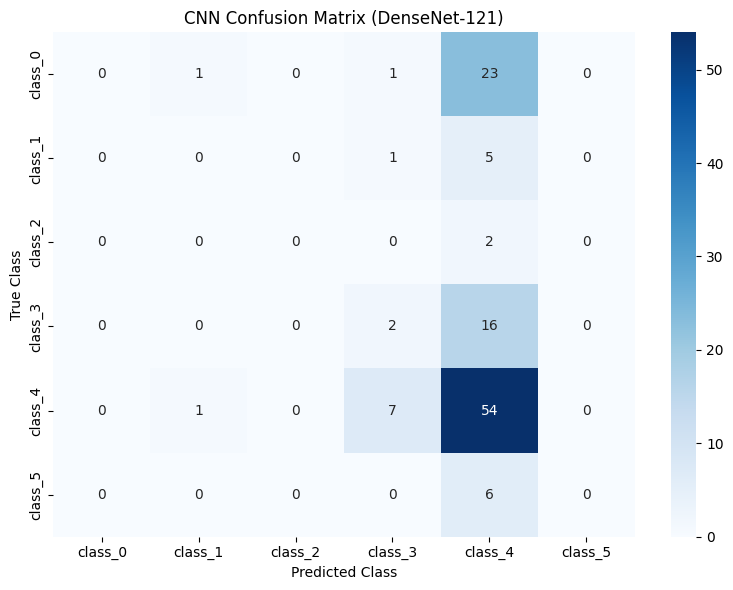


=== PER-CLASS CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

     class_0       0.00      0.00      0.00        25
     class_1       0.00      0.00      0.00         6
     class_2       0.00      0.00      0.00         2
     class_3       0.18      0.11      0.14        18
     class_4       0.51      0.87      0.64        62
     class_5       0.00      0.00      0.00         6

    accuracy                           0.47       119
   macro avg       0.12      0.16      0.13       119
weighted avg       0.29      0.47      0.36       119



Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.


In [13]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import timm

plots_dir = "/content/thesis_plots"
os.makedirs(plots_dir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn_test_dir = "/content/cnn_dataset/test"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

test_dataset = datasets.ImageFolder(root=cnn_test_dir, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)
class_names = test_dataset.classes

# 1. Initialize Best CNN Model Architecture
model_cnn = timm.create_model("densenet121", pretrained=False, num_classes=len(class_names)).to(device)

# Load saved weights if available
cnn_weights_path = "/content/thesis_cnn_results/DenseNet-121.pth"
if os.path.exists(cnn_weights_path):
    model_cnn.load_state_dict(torch.load(cnn_weights_path))
model_cnn.eval()

# 2. Run Evaluation
all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_cnn(images)
        _, preds = torch.max(outputs, 1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

# 3. Plot Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title("CNN Confusion Matrix (DenseNet-121)")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.tight_layout()
plt.savefig(os.path.join(plots_dir, "cnn_confusion_matrix.png"))
plt.show()

# 4. Output Per-Class Metrics
print("\n=== PER-CLASS CLASSIFICATION REPORT ===")
print(classification_report(all_labels, all_preds, target_names=class_names))

In [15]:
import os
import shutil

plots_dir = "/content/thesis_plots"
os.makedirs(plots_dir, exist_ok=True)

yolo_best_dir = "/content/thesis_yolo_results/YOLO11n"

# Map target filename to possible source filenames (handling legacy and new YOLO names)
artifact_mapping = {
    "confusion_matrix.png": ["confusion_matrix.png", "confusion_matrix_normalized.png"],
    "PR_curve.png": ["BoxPR_curve.png", "PR_curve.png"],
    "F1_curve.png": ["BoxF1_curve.png", "F1_curve.png"],
    "P_curve.png": ["BoxP_curve.png", "P_curve.png"],
    "R_curve.png": ["BoxR_curve.png", "R_curve.png"],
    "results.png": ["results.png"]
}

print("[+] Collecting YOLO Plot Artifacts...")
for target_name, possible_sources in artifact_mapping.items():
    found = False
    for src_name in possible_sources:
        src_path = os.path.join(yolo_best_dir, src_name)
        if os.path.exists(src_path):
            dest_path = os.path.join(plots_dir, f"yolo_{target_name}")
            shutil.copy(src_path, dest_path)
            print(f"  ✓ Copied {src_name} -> {dest_path}")
            found = True
            break

    if not found:
        print(f"  ⚠️ Could not find {target_name} (checked: {possible_sources}) in {yolo_best_dir}")

[+] Collecting YOLO Plot Artifacts...
  ✓ Copied confusion_matrix.png -> /content/thesis_plots/yolo_confusion_matrix.png
  ✓ Copied BoxPR_curve.png -> /content/thesis_plots/yolo_PR_curve.png
  ✓ Copied BoxF1_curve.png -> /content/thesis_plots/yolo_F1_curve.png
  ✓ Copied BoxP_curve.png -> /content/thesis_plots/yolo_P_curve.png
  ✓ Copied BoxR_curve.png -> /content/thesis_plots/yolo_R_curve.png
  ✓ Copied results.png -> /content/thesis_plots/yolo_results.png


In [16]:
import os
import pandas as pd

storage_data = []
search_directories = ["/content/thesis_yolo_results", "/content/thesis_cnn_results", "/content"]

print("[+] Calculating Model File Sizes on Disk...")
for target_dir in search_directories:
    if not os.path.exists(target_dir):
        continue
    for root, dirs, files in os.walk(target_dir):
        for f in files:
            if f.endswith(".pt") or f.endswith(".onnx") or f.endswith(".pth"):
                file_path = os.path.join(root, f)
                size_mb = round(os.path.getsize(file_path) / (1024 * 1024), 2)

                category = "YOLO Detector" if "yolo" in f.lower() or "yolo" in root.lower() else "CNN Classifier"

                storage_data.append({
                    "Category": category,
                    "File Name": f,
                    "Size (MB)": size_mb,
                    "Path": file_path
                })

df_storage = pd.DataFrame(storage_data)
df_storage.to_csv("/content/model_file_sizes.csv", index=False)

print("\n=== MODEL DISK STORAGE SUMMARY ===")
print(df_storage.to_markdown(index=False) if not df_storage.empty else "No saved weights found.")

[+] Calculating Model File Sizes on Disk...

=== MODEL DISK STORAGE SUMMARY ===
| Category      | File Name   |   Size (MB) | Path                                                  |
|:--------------|:------------|------------:|:------------------------------------------------------|
| YOLO Detector | last.pt     |        5.96 | /content/thesis_yolo_results/YOLOv8n/weights/last.pt  |
| YOLO Detector | best.pt     |        5.96 | /content/thesis_yolo_results/YOLOv8n/weights/best.pt  |
| YOLO Detector | last.pt     |        5.22 | /content/thesis_yolo_results/YOLO11n/weights/last.pt  |
| YOLO Detector | best.pt     |        5.22 | /content/thesis_yolo_results/YOLO11n/weights/best.pt  |
| YOLO Detector | last.pt     |        5.49 | /content/thesis_yolo_results/YOLOv10n/weights/last.pt |
| YOLO Detector | best.pt     |        5.49 | /content/thesis_yolo_results/YOLOv10n/weights/best.pt |
| YOLO Detector | last.pt     |        4.43 | /content/thesis_yolo_results/YOLOv9t/weights/last.pt  |
| 

In [17]:
from ultralytics import YOLO

print("[+] Extracting YOLO Computational GFLOPs...")

# Load your best trained model or baseline checkpoint
yolo_model = YOLO("yolo11n.pt")

print("\n=== YOLO ARCHITECTURE & GFLOPS SUMMARY ===")
yolo_model.info()

[+] Extracting YOLO Computational GFLOPs...

=== YOLO ARCHITECTURE & GFLOPS SUMMARY ===
YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs


(181, 2624080, 0, 6.6733184)